In [1]:
# Import modules
import os
import sys

# Make sure that the executable path exists in the environment path
env_bin = os.path.dirname(sys.executable)
if env_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{env_bin}:{os.environ['PATH']}"

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal
import xarray as xr
import yaml
from map_setup import setup_Weddell_Sea_figure, setup_Weddell_Sea_subplot  # , plot_peak_and_lag

with open("config.yml") as f:
    config = yaml.safe_load(f)
viz_opts = config["viz"]

In [2]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=4, threads_per_worker=4)
client = Client(cluster)
client

/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 45245 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:45245/status,
Dashboard: http://127.0.0.1:45245/status,Workers: 4
Total threads: 16,Total memory: 128.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41419,Workers: 0
Dashboard: http://127.0.0.1:45245/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45109,Total threads: 4
Dashboard: http://127.0.0.1:34215/status,Memory: 32.00 GiB
Nanny: tcp://127.0.0.1:38559,


In [3]:
inertial_wind_field = xr.open_zarr(
    "./data/inertial_wind_field.zarr"
)  # .chunk(chunks={"time": -1, "latitude": 100, "longitude": 100})

In [4]:
inertial_wind_field  #

<xarray.Dataset> Size: 4GB
Dimensions:        (time: 13140, latitude: 161, longitude: 221)
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(13140,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    isobaricInhPa  float64 8B ...
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>

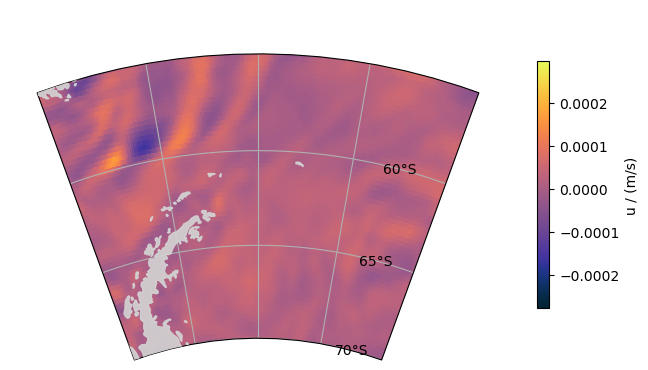

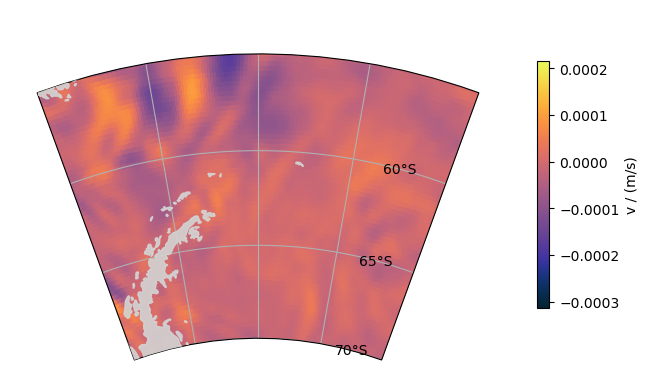

In [5]:
lat = inertial_wind_field.variables["latitude"][:]  # latitude grid points
lon = inertial_wind_field.variables["longitude"][:]  # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea_figure(fig)
im = ax.pcolormesh(
    lon,
    lat,
    inertial_wind_field.variables["u"].mean(dim="time"),
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
)
# ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder = 10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="u / (m/s)")

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea_figure(fig)
im = ax.pcolormesh(
    lon,
    lat,
    inertial_wind_field.variables["v"].mean(dim="time"),
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="v / (m/s)");

# Site C

In [6]:
dissip_df = pd.read_csv(
    "./data/wave_induced_dissipation_rate_time_series_at_C.csv", parse_dates=[0], index_col=0
)
dissip_df

,0
2017-02-12,8.252667e-10
2017-02-17,8.708783e-10
2017-02-22,8.313334e-10
2017-02-27,9.406800e-10
2017-03-04,1.544095e-09
...,...
2018-12-24,9.840217e-10
2018-12-29,1.178971e-09
2019-01-03,1.208642e-09
2019-01-08,1.308510e-09


In [7]:
inertial_wind_field

<xarray.Dataset> Size: 4GB
Dimensions:        (time: 13140, latitude: 161, longitude: 221)
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(13140,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    isobaricInhPa  float64 8B ...
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>

In [8]:
dissip_at_C = xr.DataArray(
    dissip_df.iloc[:, 0].values,
    coords={"time": dissip_df.index.values},
    dims="time",
    name="wave_induced_dissipation_rate",
)  # .expand_dims(lat=[-63.66], lon=[-50.81])
dissip_at_C

<xarray.DataArray 'wave_induced_dissipation_rate' (time: 141)> Size: 1kB
array([8.25266718e-10, 8.70878328e-10, 8.31333387e-10, 9.40680025e-10,
       1.54409507e-09, 2.08923747e-09, 1.93618828e-09, 4.44914276e-09,
       5.14715498e-09, 4.48823456e-09, 2.75275172e-09, 2.76327187e-09,
       1.39202034e-09, 1.18803579e-09, 8.95673709e-10, 7.76001232e-10,
       1.09345469e-09, 1.53070988e-09, 1.64571824e-09, 1.73716929e-09,
       1.93351003e-09, 1.63080767e-09, 1.42571603e-09, 1.60794925e-09,
       1.32303939e-09, 1.09757885e-09, 1.08385722e-09, 6.84486763e-10,
       6.81412810e-10, 7.93094294e-10, 1.03039976e-09, 2.03833600e-09,
       3.21357644e-09, 2.94929495e-09, 3.41352299e-09, 2.67930362e-09,
       2.19238235e-09, 1.19724155e-09, 1.40644029e-09, 1.79470954e-09,
       2.37370658e-09, 2.73249286e-09, 2.17825838e-09, 2.70597015e-09,
       2.37208742e-09, 2.06713013e-09, 1.86207848e-09, 1.84901655e-09,
       1.53353125e-09, 1.60859064e-09, 1.33255317e-09, 1.43038155e-09,
       1.44429168e-09, 1.15680279e-09, 1.13468754e-09, 1.86844186e-09,
       1.99524985e-09, 1.96132034e-09, 2.77080020e-09, 2.74814690e-09,
       1.77733962e-09, 1.53881166e-09, 1.27261075e-09, 1.28514047e-09,
       5.48475974e-10, 4.69900035e-10, 6.58133498e-10, 7.72535224e-10,
       7.32413864e-10, 9.41193017e-10, 9.07800412e-10, 9.01453432e-10,
       7.09630318e-10, 9.01690922e-10, 1.04752986e-09, 1.79257677e-09,
       1.73317026e-09, 1.52359328e-09, 1.78691869e-09, 1.77296612e-09,
       1.57916755e-09, 1.67504601e-09, 1.86289423e-09, 1.70732947e-09,
       1.52582748e-09, 1.58464699e-09, 9.85583603e-10, 1.60465722e-09,
       1.69687600e-09, 1.89625069e-09, 1.85528772e-09, 1.87923311e-09,
       1.22447271e-09, 1.39275482e-09, 1.07487930e-09, 6.93929089e-10,
       1.16521789e-09, 9.70747326e-10, 8.91538584e-10, 1.04559092e-09,
       9.04955884e-10, 7.68511092e-10, 9.31990451e-10, 9.93331273e-10,
       1.27798839e-09, 2.47600689e-09, 2.63873234e-09, 2.80509526e-09,
       3.80071196e-09, 3.73040318e-09, 2.55550021e-09, 2.39833329e-09,
       2.13965354e-09, 1.95221630e-09, 1.64858182e-09, 1.20046303e-09,
       1.05534248e-09, 1.39686457e-09, 1.47384565e-09, 1.84807020e-09,
       2.60223595e-09, 2.60130825e-09, 2.44736055e-09, 1.93200494e-09,
       1.38088137e-09, 1.59534748e-09, 1.65477364e-09, 1.86543452e-09,
       3.14083394e-09, 3.91472138e-09, 2.51719565e-09, 2.50288586e-09,
       2.43765721e-09, 1.40484145e-09, 9.96852603e-10, 9.20337869e-10,
       9.84021716e-10, 1.17897058e-09, 1.20864240e-09, 1.30851038e-09,
       1.14914084e-09])
Coordinates:
  * time     (time) datetime64[us] 1kB 2017-02-12 2017-02-17 ... 2019-01-13

In [9]:
trimmed_inertial_wind_field = inertial_wind_field.sel(time=slice("2017-02-12", "2019-01-13"))
inertial_wind_speed = abs(
    trimmed_inertial_wind_field["u"] + 1j * trimmed_inertial_wind_field["v"]
).chunk({"time": -1, "latitude": 80, "longitude": 80})

seasonal_inertial_wind_strength = (
    inertial_wind_speed.resample(time="5D")
    .mean()
    .rolling(time=3, min_periods=1)
    .mean()  # equivalent to 15D
)

In [10]:
seasonal_inertial_wind_strength = seasonal_inertial_wind_strength.persist()

In [11]:
corr_map_around_C = xr.corr(dissip_at_C, seasonal_inertial_wind_strength, dim="time")
corr_map_around_C = corr_map_around_C.compute()
corr_map_around_C

<xarray.DataArray (latitude: 161, longitude: 221)> Size: 285kB
array([[ 0.09905153,  0.0228131 , -0.04736557, ..., -0.11703954,
        -0.10840091, -0.09994146],
       [ 0.12078003,  0.09271633, -0.00325558, ..., -0.08827392,
        -0.08667781, -0.0809467 ],
       [ 0.10660294,  0.05675577, -0.02824893, ..., -0.0590959 ,
        -0.06766506, -0.07090193],
       ...,
       [ 0.17624178,  0.17665647,  0.17687216, ...,  0.1470774 ,
         0.14655318,  0.14624412],
       [ 0.1707347 ,  0.17088238,  0.17084548, ...,  0.14393366,
         0.14358508,  0.14334247],
       [ 0.07680646,  0.07680646,  0.07680646, ...,  0.07680646,
         0.07680646,  0.07680646]])
Coordinates:
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    isobaricInhPa  float64 8B 1e+03
    number         int64 8B 0
    step           timedelta64[ns] 8B 00:00:00
Attributes: (12/24)
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      35581
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_longitudeOfFirstGridPointInDegrees:  -75.0
    GRIB_longitudeOfLastGridPointInDegrees:   -20.0
    GRIB_missingValue:                        3.4028234663852886e+38
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    units:                                    m s**-1

In [12]:
# corr_map_around_C.compute()

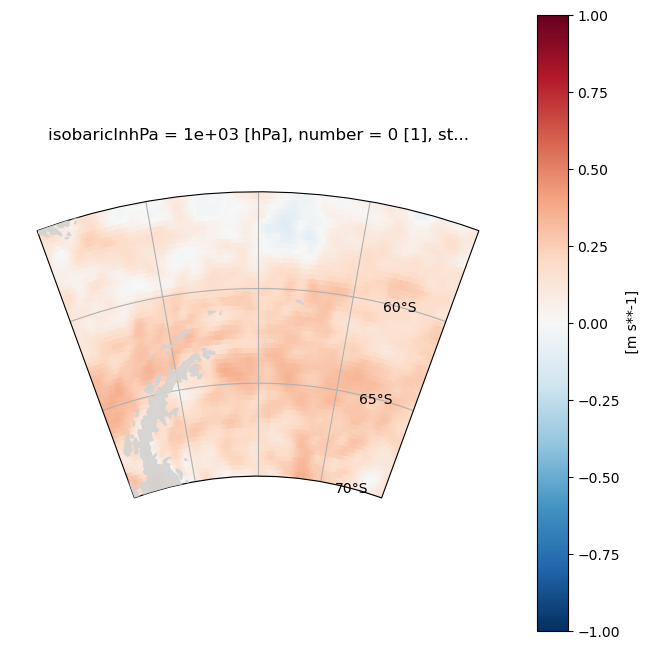

In [13]:
# lat = inertial_wind_field.variables['latitude'][:] # latitude grid points
# lon = inertial_wind_field.variables['longitude'][:] # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea_figure(fig)
corr_map_around_C.plot(
    x="longitude", y="latitude", ax=ax, vmin=-1, vmax=1, cmap="RdBu_r", transform=ccrs.PlateCarree()
)

# im= ax.pcolormesh(lon, lat, inertial_wind_field.isel(time=0).variables['u'], transform=ccrs.PlateCarree(), cmap = cm.cm.thermal)
# #ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder = 10)
# #ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
# plt.colorbar(im, orientation='vertical', shrink = 0.4, label="u / (m/s)");

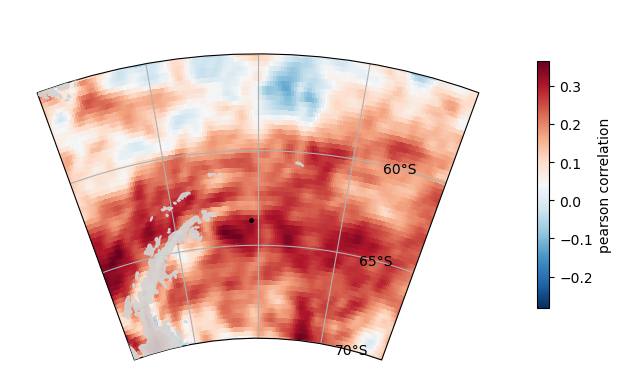

In [14]:
lat = corr_map_around_C["latitude"]  # latitude grid points
lon = corr_map_around_C["longitude"]  # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea_figure(fig)
im = ax.pcolormesh(lon, lat, corr_map_around_C, transform=ccrs.PlateCarree(), cmap="RdBu_r")
ax.plot([-50.81], [-63.66], color="k", marker=".", ms=5, ls="None", transform=ccrs.PlateCarree())

plt.colorbar(im, orientation="vertical", shrink=0.4, label="pearson correlation");
# fig.savefig("pearson_corr_around_C.svg")

# Cross Correlation around C

In [15]:
def normalized_crosscorr(a, b):
    n = len(a)
    c = signal.correlate(a - a.mean(), b - b.mean(), mode="same")
    return c / (n * np.std(a) * np.std(b))


dissip, wind = xr.align(dissip_at_C, seasonal_inertial_wind_strength, join="inner")
dissip = dissip.chunk({"time": -1})
wind = wind.chunk({"time": -1})

n = wind.sizes["time"]
lags = signal.correlation_lags(n, n, mode="same")

# time step derived from the data (most common spacing)
dt = pd.Series(dissip.time.values).diff().dropna().mode()[0]
lag_time = lags * dt.to_timedelta64()

full_xcorr_map_around_C = (
    xr.apply_ufunc(
        normalized_crosscorr,
        dissip,
        wind,
        input_core_dims=[["time"], ["time"]],
        output_core_dims=[["lag"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[np.float64],
        dask_gufunc_kwargs={"output_sizes": {"lag": n}},
    )
    .assign_coords(
        lag=lag_time,  # timedelta64 coordinate (main)
        lag_samples=("lag", lags),  # integer offsets, handy for debugging
    )
    .transpose("lag", "latitude", "longitude")
)

In [16]:
max_lag = pd.Timedelta(days=40)

xcorr_map_around_C = full_xcorr_map_around_C.sel(lag=slice(-max_lag, max_lag))
xcorr_map_around_C.compute()

<xarray.DataArray 'wave_induced_dissipation_rate' (lag: 17, latitude: 161,
                                                   longitude: 221)> Size: 5MB
array([[[ 0.03608604,  0.07968172,  0.02736424, ...,  0.00117352,
         -0.01615106, -0.04036958],
        [ 0.07786362,  0.07153876, -0.00751982, ...,  0.00240802,
         -0.00674483, -0.02648868],
        [ 0.16835155,  0.14830639,  0.03210441, ..., -0.01262669,
         -0.01138332, -0.01616527],
        ...,
        [-0.03154201, -0.03208401, -0.03230727, ..., -0.04615569,
         -0.04591683, -0.04560395],
        [-0.03747663, -0.03767837, -0.03788821, ..., -0.05799014,
         -0.05788258, -0.05791728],
        [-0.08395355, -0.08395355, -0.08395355, ..., -0.08395355,
         -0.08395355, -0.08395355]],

       [[ 0.0665883 ,  0.11929823,  0.08769076, ..., -0.06328142,
         -0.08436637, -0.10865215],
        [ 0.12271031,  0.15185862,  0.06637487, ..., -0.06446072,
         -0.07479786, -0.09366814],
        [ 0.20212329,  0.21132218,  0.08349904, ..., -0.07978324,
         -0.07635926, -0.07999404],
...
        [ 0.06907979,  0.06899072,  0.06881564, ...,  0.03644465,
          0.0361605 ,  0.03572902],
        [ 0.07221974,  0.07215002,  0.07215832, ...,  0.06202074,
          0.06217167,  0.06200481],
        [ 0.00826217,  0.00826217,  0.00826217, ...,  0.00826217,
          0.00826217,  0.00826217]],

       [[ 0.00873568,  0.05403919,  0.0695135 , ...,  0.36762232,
          0.37780852,  0.38647968],
        [ 0.00762785,  0.03171854,  0.05177382, ...,  0.30254517,
          0.32068351,  0.33629142],
        [ 0.00071127,  0.02327382,  0.03920721, ...,  0.26033629,
          0.28836215,  0.30328111],
        ...,
        [ 0.15177089,  0.15180771,  0.15176722, ...,  0.10032129,
          0.09993254,  0.09931847],
        [ 0.15046433,  0.15047226,  0.15049569, ...,  0.13275117,
          0.13280556,  0.13259846],
        [ 0.06651161,  0.06651161,  0.06651161, ...,  0.06651161,
          0.06651161,  0.06651161]]])
Coordinates:
  * lag            (lag) timedelta64[us] 136B -40 days -35 days ... 40 days
    lag_samples    (lag) int64 136B -8 -7 -6 -5 -4 -3 -2 -1 0 1 2 3 4 5 6 7 8
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    isobaricInhPa  float64 8B 1e+03
    number         int64 8B 0
    step           timedelta64[ns] 8B 00:00:00

In [17]:
xcorr_map_around_C = xcorr_map_around_C.compute()

# window edge in days, taken from the data
max_lag_in_days = float(np.abs(xcorr_map_around_C["lag"] / np.timedelta64(1, "D")).max())
# assert max_lag_in_days == 100

# Only positive correlations
# peak = xcorr_map_around_C.max(dim="lag", skipna=True)
# lag_of_peak = xcorr_map_around_C.idxmax(dim="lag", skipna=True) / np.timedelta64(1, "D")

# Positive and negative correlations
idx = (
    np.abs(xcorr_map_around_C).fillna(-1).argmax(dim="lag")
)  # mask of highest absolute values over all lags
peak = xcorr_map_around_C.isel(lag=idx).where(
    xcorr_map_around_C.notnull().any("lag")
)  # select signed values where highest absolute values are
lag_of_peak = (xcorr_map_around_C["lag"].isel(lag=idx) / np.timedelta64(1, "D")).where(
    peak.notnull()
)

In [18]:
# Cross check if the maximum does not lay on specified maximum lag
at_edge = np.abs(lag_of_peak) >= max_lag_in_days - 1e-9  # NaN -> False
ydim, xdim = peak.dims  # assumes (lat, lon)
xc, yc = peak[xdim].values, peak[ydim].values
edge_arr = at_edge.transpose(ydim, xdim).values.astype(float)

In [19]:
# def plot_peak_and_lag(peaks,lag_of_peaks, peak_corr_cutoff, hatch="...", cmap_peak="viridis", cmap_lag="RdBu_r",
#                       figsize=(14, 6)):
#     """
#     Plot the peak cross-correlation and the lag at which it occurs on Weddell Sea maps.
#     Grid points whose peak sits at the edge of the lag window are hatched in both panels.

#     xcorr : DataArray with dims (lat, lon, lag); 'lag' is a timedelta64 coordinate.
#     """
#     fig = plt.figure(figsize=figsize)
#     axes = [setup_Weddell_Sea_subplot(fig, 121), setup_Weddell_Sea_subplot(fig, 122)]

#     peaks.where(np.abs(peaks) >= peak_corr_cutoff).plot(
#         ax=axes[0], transform=ccrs.PlateCarree(), cmap=cmap_peak, center=0,
#         cbar_kwargs={"label": "Peak cross-correlation", "shrink": 0.7, "pad": 0.1},
#         rasterized=True,
#     )
#     axes[0].set_title("Peak correlation")

#     lag_of_peaks.where(np.abs(peaks) >= peak_corr_cutoff).plot(
#         ax=axes[1], transform=ccrs.PlateCarree(), cmap=cmap_lag, center=0, robust=True,
#         cbar_kwargs={"label": "Lag of peak / days", "shrink": 0.7, "pad": 0.1},
#         rasterized=True,
#     )

#     negative_corr_mask = peaks<0
#     cs = axes[1].contourf(
#         xc, yc, negative_corr_mask, levels=[0.5, 1.5], colors="None",
#         hatches=[hatch],transform=ccrs.PlateCarree(), zorder=2,
#     )
#     cs.set_edgecolor("grey") # sets hatchcolor in a soon to be deprecated way

#     # axes[1].contour(
#     #     xc, yc, negative_corr_mask, levels=[0.5, 1.5], colors="grey", transform=ccrs.PlateCarree(), zorder=2,
#     #     )
#     axes[1].legend(
#         handles=[mpatches.Patch(facecolor="none", edgecolor="grey", hatch=hatch, label=f"peak < 0")],
#         loc="lower center", framealpha=0.9,
#     )

#     # lag_of_peaks.plot(
#     #     ax=axes[1], transform=ccrs.PlateCarree(), cmap=cmap_lag, center=0, robust=True,
#     #     cbar_kwargs={"label": "Lag of peak [days]", "shrink": 0.7, "pad": 0.1},
#     # )
#     axes[1].set_title("Lag of peak (positive: wind leads)")

#     # peak_corr_cutoff = 0.2
#     # ydim, xdim = peaks.dims
#     # weak_corr = (np.abs(peaks) <= peak_corr_cutoff).transpose(ydim, xdim).values.astype(float)  # NaN -> False

#     # if weak_corr.any():
#     #     axes[1].contourf(
#     #         xc, yc, weak_corr, levels=[0.5, 1.5], colors="grey",
#     #         hatches=[hatch], transform=ccrs.PlateCarree(), zorder=2,
#     #     )
#     #     axes[1].contour(
#     #         xc, yc, weak_corr, levels=[0.5, 1.5], colors="grey", transform=ccrs.PlateCarree(), zorder=2,
#     #     )
#     #     axes[1].legend(
#     #         handles=[mpatches.Patch(facecolor="none", edgecolor="k", hatch=hatch, label=f"peak <= {peak_corr_cutoff:.1f}")],
#     #         loc="lower left", framealpha=0.9,
#     #     )

#     # # hatch edge-peak regions in both panels
#     # if edge_arr.any():
#     #     for ax in axes:
#     #         ax.contourf(xc, yc, edge_arr, levels=[0.5, 1.5], colors="none",
#     #                     hatches=[hatch], transform=ccrs.PlateCarree(), zorder=2)
#     # axes[1].legend(
#     #     handles=[mpatches.Patch(facecolor="none", edgecolor="k", hatch=hatch,
#     #                    label=f"peak at ±{max_lag:.0f} d")],
#     #     loc="lower left", framealpha=0.9,
#     # )

#     return fig, axes

In [37]:
def plot_peak_and_lag(
    peaks,
    lag_of_peaks,
    peak_corr_cutoff,
    cmap_peak,
    peak_norm,
    cmap_lag,
    lag_norm,
    hatch="///",
    figsize=(14, 6),
):
    """
    Plot the peak cross-correlation and the lag at which it occurs on Weddell Sea maps.
    Grid points whose peak sits at the edge of the lag window are hatched in both panels.

    xcorr : DataArray with dims (lat, lon, lag); 'lag' is a timedelta64 coordinate.
    """
    fig = plt.figure(figsize=figsize)
    axes = [setup_Weddell_Sea_subplot(fig, 121), setup_Weddell_Sea_subplot(fig, 122)]

    peaks.where(np.abs(peaks) >= peak_corr_cutoff).plot(
        ax=axes[0],
        transform=ccrs.PlateCarree(),
        cmap=cmap_peak,
        norm=peak_norm,
        center=0,
        cbar_kwargs={"label": "Peak cross-correlation", "shrink": 0.4, "pad": 0.1},
        rasterized=True,
    )
    axes[0].set_title("Peak correlation")

    lag_of_peaks.where(np.abs(peaks) >= peak_corr_cutoff).plot(
        ax=axes[1],
        transform=ccrs.PlateCarree(),
        cmap=cmap_lag,
        norm=lag_norm,
        center=0,
        robust=True,
        cbar_kwargs={"label": "Lag of peak / days", "shrink": 0.4, "pad": 0.1},
        rasterized=True,
    )

    negative_corr_mask = peaks.where(np.abs(peaks) >= peak_corr_cutoff) < 0
    cs = axes[1].contourf(
        xc,
        yc,
        negative_corr_mask,
        levels=[0.5, 1.5],
        colors="None",
        hatches=[hatch],
        transform=ccrs.PlateCarree(),
        zorder=2,
    )
    # cs.set_edgecolor("grey") # sets hatchcolor in a soon to be deprecated way

    # axes[1].contour(
    #     xc, yc, negative_corr_mask, levels=[0.5, 1.5], colors="grey", transform=ccrs.PlateCarree(), zorder=2,
    #     )
    axes[1].legend(
        handles=[mpatches.Patch(facecolor="none", edgecolor="grey", hatch=hatch, label="peak < 0")],
        loc="lower center",
        framealpha=0.9,
    )

    # lag_of_peaks.plot(
    #     ax=axes[1], transform=ccrs.PlateCarree(), cmap=cmap_lag, center=0, robust=True,
    #     cbar_kwargs={"label": "Lag of peak [days]", "shrink": 0.7, "pad": 0.1},
    # )
    axes[1].set_title("Lag of peak (positive: wind leads)")

    peak_corr_cutoff = 0.2
    ydim, xdim = peaks.dims
    weak_corr = (
        (np.abs(peaks) <= peak_corr_cutoff).transpose(ydim, xdim).values.astype(float)
    )  # NaN -> False

    # if weak_corr.any():
    #     axes[1].contourf(
    #         xc, yc, weak_corr, levels=[0.5, 1.5], colors="grey",
    #         hatches=[hatch], transform=ccrs.PlateCarree(), zorder=2,
    #     )
    #     axes[1].contour(
    #         xc, yc, weak_corr, levels=[0.5, 1.5], colors="grey", transform=ccrs.PlateCarree(), zorder=2,
    #     )
    #     axes[1].legend(
    #         handles=[mpatches.Patch(facecolor="none", edgecolor="k", hatch=hatch, label=f"peak <= {peak_corr_cutoff:.1f}")],
    #         loc="lower left", framealpha=0.9,
    #     )

    # hatch edge-peak regions in both panels
    # if edge_arr.any():
    #     for ax in axes:
    #         ax.contourf(xc, yc, edge_arr, levels=[0.5, 1.5], colors="none",
    #                     hatches=[hatch], transform=ccrs.PlateCarree(), zorder=2)
    # axes[1].legend(
    #     handles=[mpatches.Patch(facecolor="none", edgecolor="k", hatch=hatch,
    #                    label=f"peak at ±{max_lag_in_days:.0f} d")],
    #     loc="lower left", framealpha=0.9,
    # )

    return fig, axes

In [28]:
# from matplotlib.colors import LinearSegmentedColormap

# cmap_lag = LinearSegmentedColormap.from_list(
#     "dark_center_div",
#     [
#         (0.00, "#b8ecf5"),   # strongly negative: light cyan
#         (0.25, "#2c7fb8"),   # blue
#         (0.50, "#2a1a5e"),   # zero: deep indigo (most saturated/dark)
#         (0.75, "#c0392b"),   # red
#         (1.00, "#ffe9a8"),   # strongly positive: light yellow
#     ],
#     N=256,
# )

In [35]:
peak_corr_cutoff = 0.2
vmax = 0.5
step = 0.1

bounds = np.concatenate(
    (
        np.arange(-vmax, -peak_corr_cutoff + step, step),
        np.arange(peak_corr_cutoff, vmax + step, step),
    )
).round(10)

n_side = (len(bounds) - 2) // 2  # 5 colors per side
base = cm.cm.curl

# Stop short of the extreme end so the "over" color can be darker than the last bin
pos = np.linspace(0.6, 0.9, n_side)
neg = 1.0 - pos[::-1]  # mirrored around curl's midpoint
colors = np.vstack([base(neg), [(1, 1, 1, 1)], base(pos)])

cmap_peak = mcolors.ListedColormap(colors, name="curl_discrete")
cmap_peak.set_over(base(1.0))  # color for values > vmax

peak_norm = mcolors.BoundaryNorm(bounds, cmap_peak.N)
boundaries = np.linspace(-max_lag_in_days, +max_lag_in_days, 17)
lag_norm = mcolors.BoundaryNorm(boundaries=boundaries, ncolors=256, extend="both")

array([-40., -35., -30., -25., -20., -15., -10.,  -5.,   0.,   5.,  10.,
        15.,  20.,  25.,  30.,  35.,  40.])

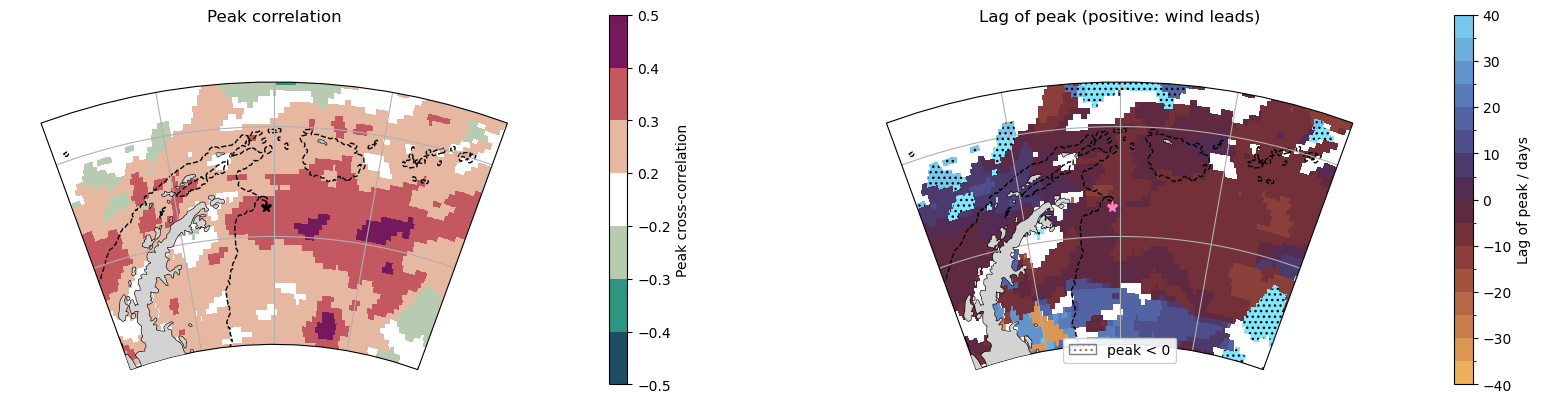

In [38]:
fig, axes = plot_peak_and_lag(
    peak,
    lag_of_peak,
    peak_corr_cutoff=peak_corr_cut_off,
    hatch="...",
    cmap_peak=cmap_peak,
    peak_norm=peak_norm,
    cmap_lag="managua",
    lag_norm=lag_norm,
    figsize=(20, 12),
)

# cartopy magic to add the 1000m isobath, taken from https://github.com/SciTools/cartopy/issues/1586
from shapely.ops import unary_union

bathym = cfeature.NaturalEarthFeature(name="bathymetry_J_1000", scale="10m", category="physical")
bathym = unary_union(list(bathym.geometries()))
from shapely.geometry import JOIN_STYLE

delta = 0.0001  # Increase eps depending on your contour resolution
bathym = bathym.buffer(delta, 1, join_style=JOIN_STYLE.mitre).buffer(
    -delta, 1, join_style=JOIN_STYLE.mitre
)
axes[0].add_geometries(
    bathym,
    facecolor="none",
    edgecolor="black",
    linestyle="dashed",
    linewidth=1,
    crs=ccrs.PlateCarree(),
)
axes[1].add_geometries(
    bathym,
    facecolor="none",
    edgecolor="black",
    linestyle="dashed",
    linewidth=1,
    crs=ccrs.PlateCarree(),
)
axes[0].add_feature(cfeature.LAND, facecolor="lightgrey", zorder=10)
axes[1].add_feature(cfeature.LAND, facecolor="lightgrey", zorder=10)

axes[0].plot(
    [-50.81], [-63.66], color="k", marker="*", ms=8, ls="None", transform=ccrs.PlateCarree()
)
axes[1].plot(
    [-50.81], [-63.66], color="xkcd:pink", marker="*", ms=8, ls="None", transform=ccrs.PlateCarree()
)
fig.savefig("f08_peaks_and_lags_map.svg", dpi=400)